In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!rm -rf /content/work
!mkdir -p /content/work/outputs /content/work/models
!unzip -q /content/drive/MyDrive/PanVision/crops.zip -d /content/work/outputs
!unzip -q /content/drive/MyDrive/PanVision/code.zip -d /content/work
!cp /content/drive/MyDrive/PanVision/densenet_best.pt /content/work/models/densenet_best.pt
!pip install -q grad-cam
!ls /content/work /content/work/models

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
/content/work:
models	outputs  research  src

/content/work/models:
densenet_best.pt


In [ ]:
%cd /content/work
!python src/explainability/build_embeddings.py --model models/densenet_best.pt --crops outputs/crops --out outputs/embeddings_densenet.npz

/content/work
Model from epoch 5 (validation AUC 0.9287383673989716), running on cuda
train: 32869 pictures from 1551 patients
val: 6818 pictures from 334 patients
test: 7004 pictures from 334 patients

Saved 2233 study fingerprints to outputs/embeddings_densenet.npz


In [ ]:
!python src/explainability/evaluate_retrieval.py --embeddings outputs/embeddings_densenet.npz --split val

Database: 1551 training patients (469 PDAC)
Queries : 334 val patients (101 PDAC)

Precision@3, all queries : 0.86  (random baseline 0.58)
Precision@3, PDAC queries: 0.71  (random baseline 0.30)
At least one of the 3 has the same label: 91% of queries

A useful model must beat the random baseline, especially for PDAC queries.


In [ ]:
!cp outputs/embeddings_densenet.npz /content/drive/MyDrive/PanVision/embeddings_densenet.npz

In [ ]:
%cd /content/work
!python src/explainability/slice_localisation.py --model models/densenet_best.pt --split val

/content/work
98 PDAC studies in val with reference tumour slices
Share of the top-3 slices that are tumour slices: 0.68  (chance 0.37)
At least one of the top-3 is a tumour slice: 89% of studies
The first number should be clearly higher than chance.


/content/work
Study 100003_00001 (val, true label PDAC)
Patient score 0.630  threshold 0.10  ->  PDAC
   slice 32: 1.00 | reference tumour slice
   slice 33: 1.00 | reference tumour slice
   slice 35: 1.00 | reference tumour slice
Saved outputs/gradcam_densenet_100003_00001.png
Study 100007_00001 (val, true label non-PDAC)
Patient score 0.010  threshold 0.10  ->  non-PDAC
   slice 130: 0.16
   slice 133: 0.04
   slice 131: 0.02
Saved outputs/gradcam_densenet_100007_00001.png


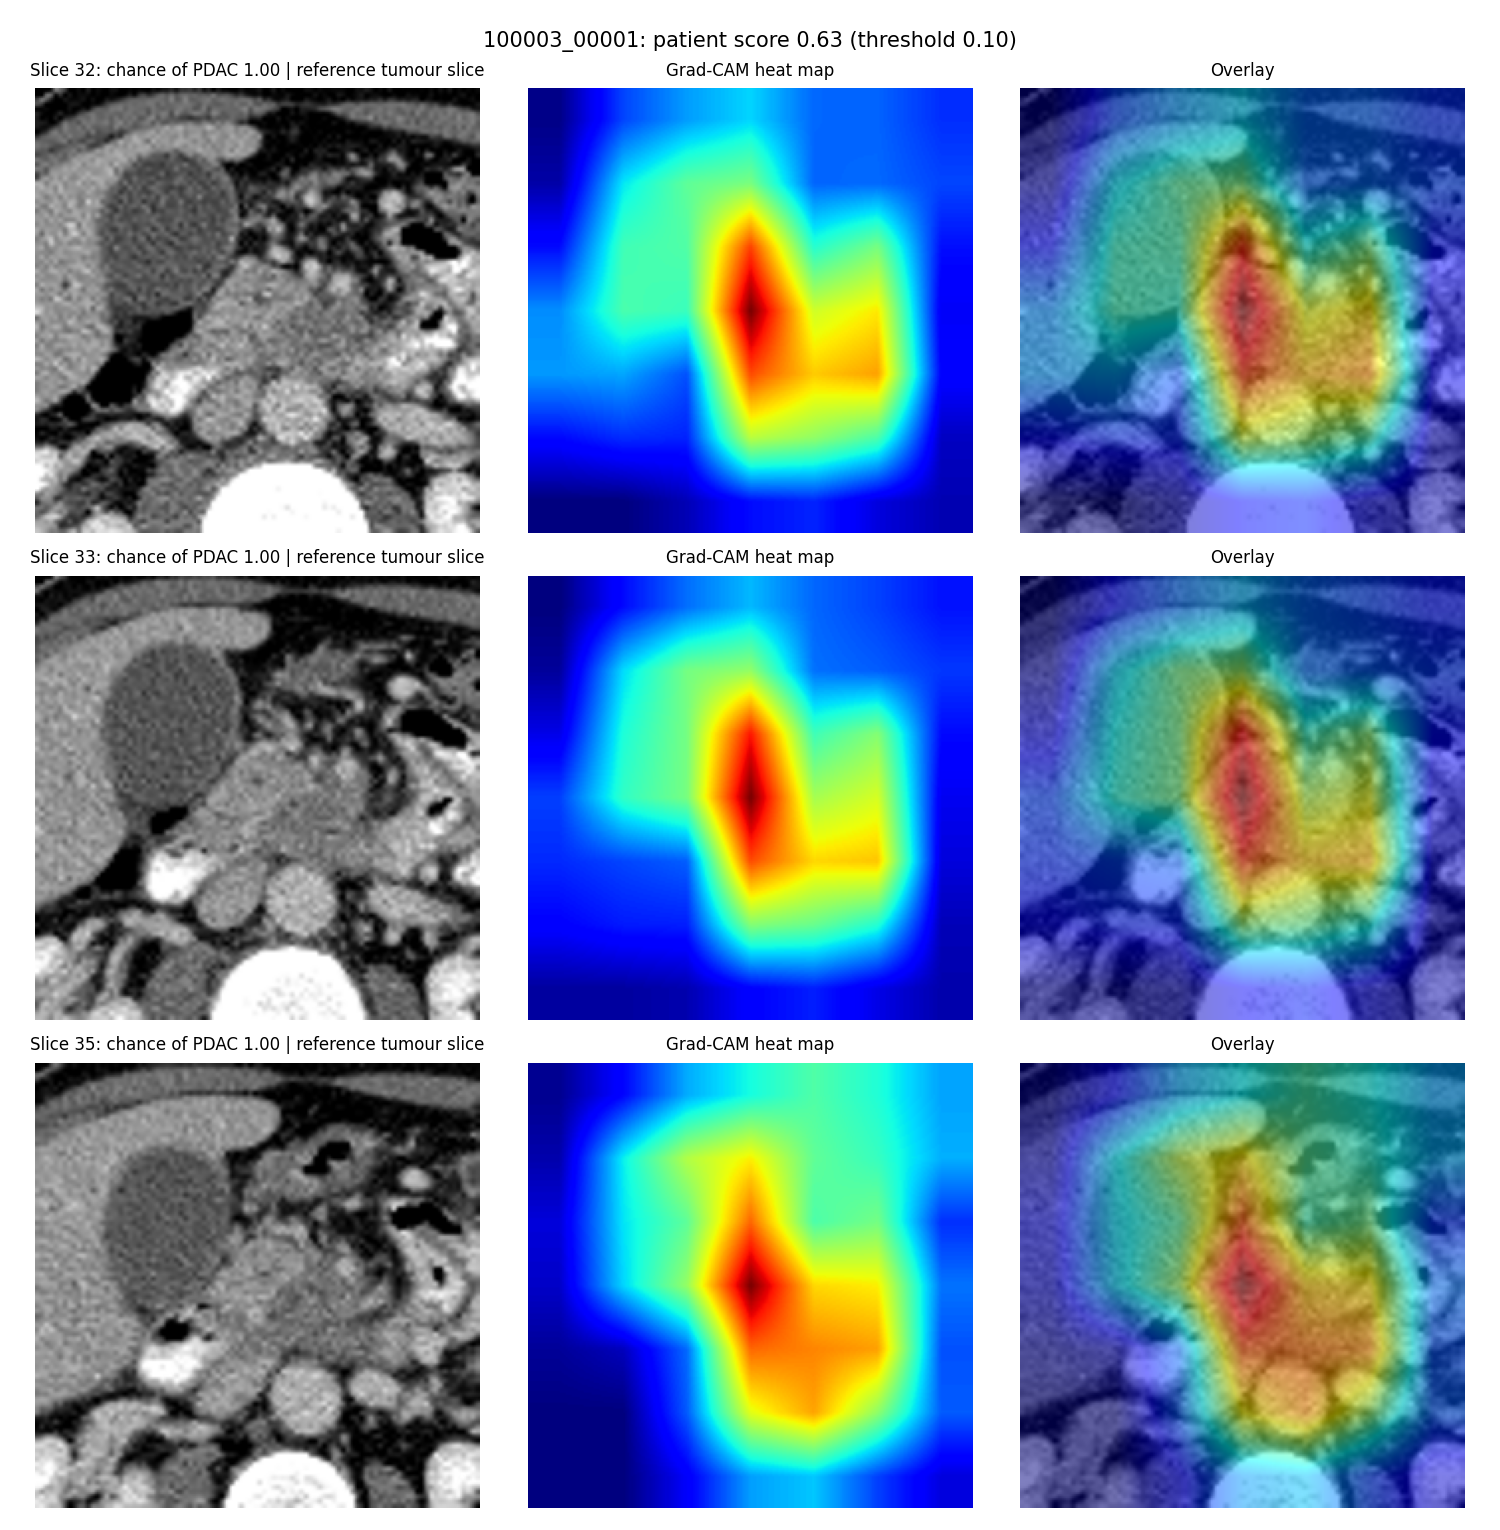

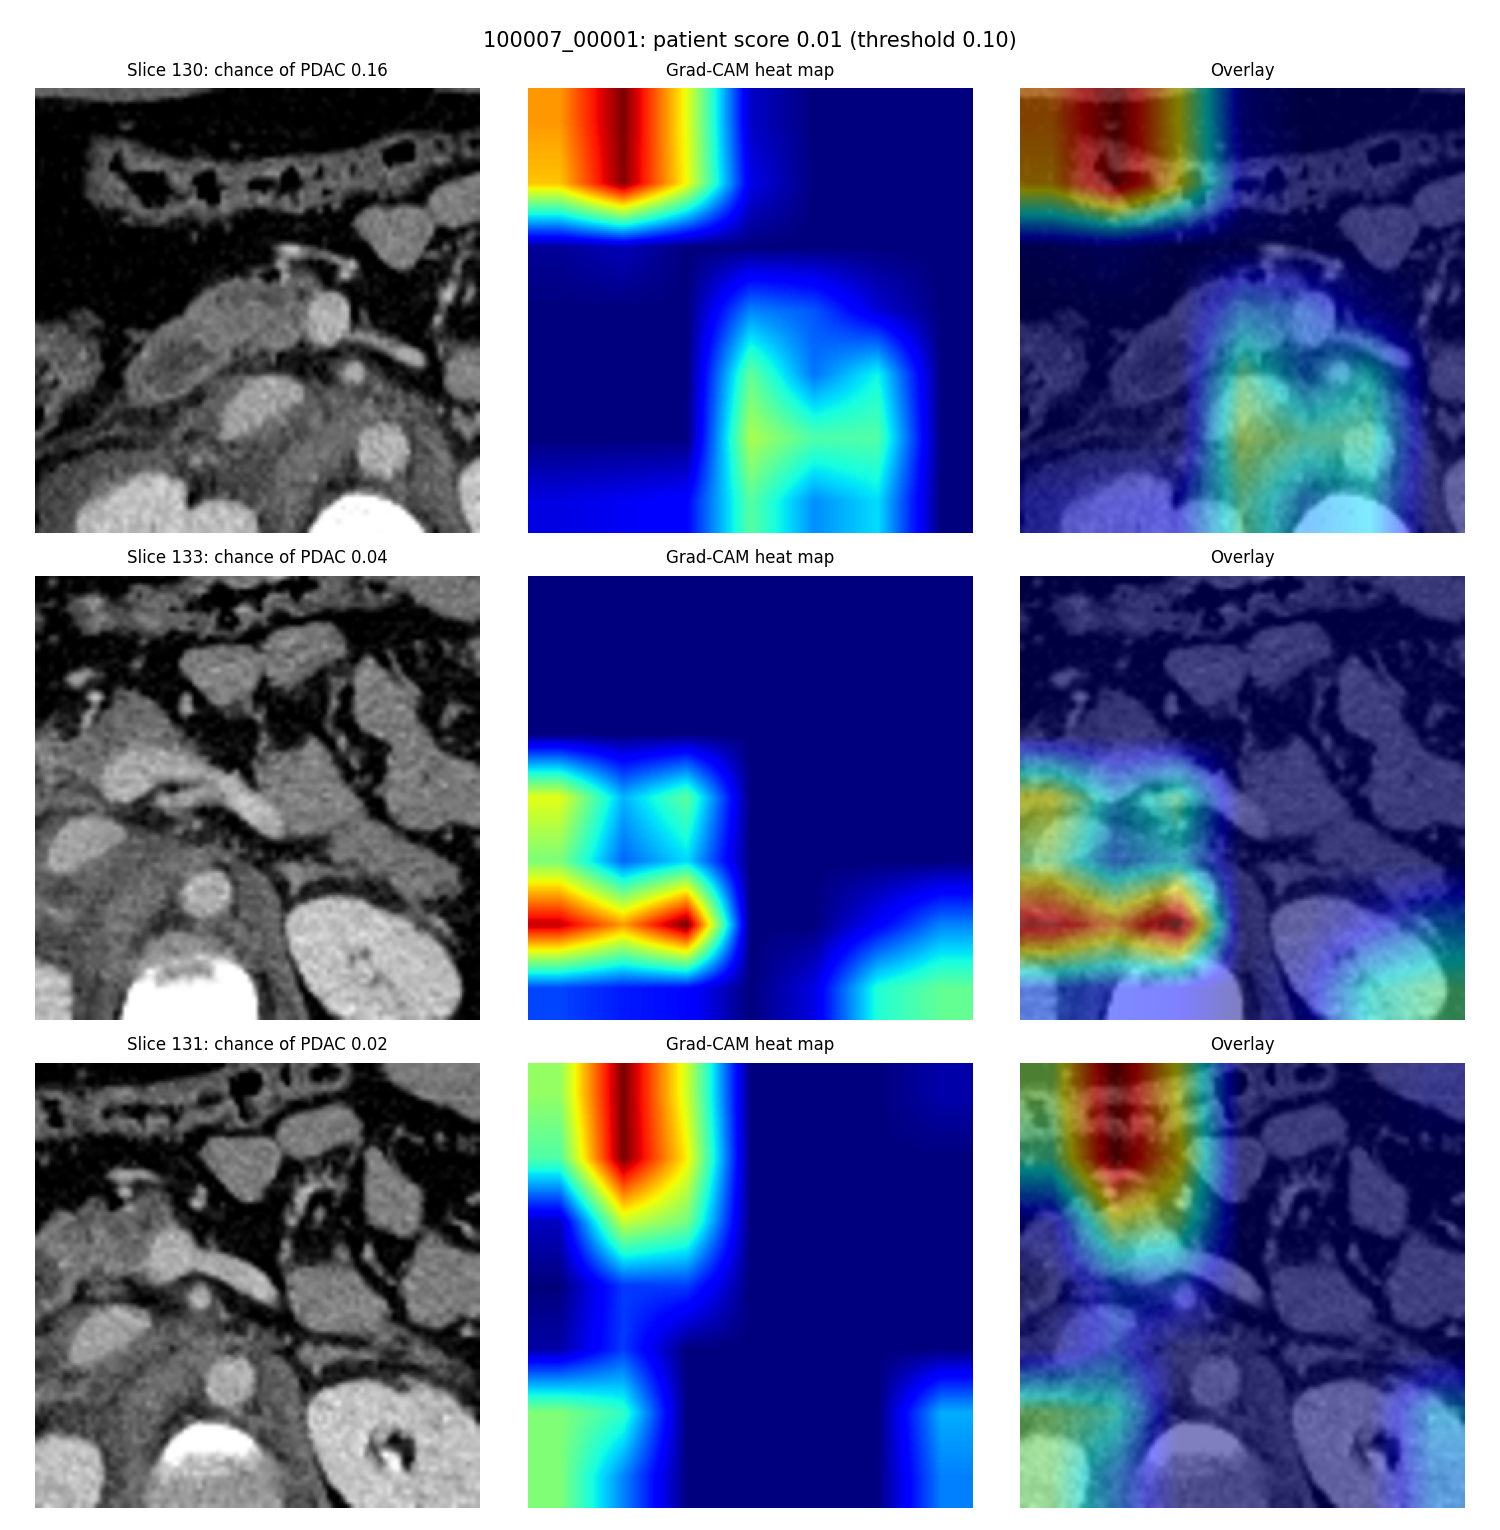

In [3]:
%cd /content/work
for s in ('100003_00001', '100007_00001'):
       !python src/explainability/gradcam_patient.py {s} --model models/densenet_best.pt --crops outputs/crops --out outputs/gradcam_densenet_{s}.png
from IPython.display import Image, display
for s in ('100003_00001', '100007_00001'):
       display(Image(f'outputs/gradcam_densenet_{s}.png'))